# 05 — Final results: 10k suite, baselines, fairness, red team, NNPA timing

Reads `artifacts/sim/simulate.json`, `artifacts/sim/redteam.json` and `artifacts/bench/throughput.json`.
These are the only sources for numbers on the slides and in the model card.

In [1]:
import json, os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ART = Path(os.environ.get("NYAYA_ARTIFACTS", Path.home() / "shared" / "nyaya" / "artifacts"))
pd.set_option("display.width", 200)

In [2]:
sim = json.loads((ART / "sim" / "simulate.json").read_text())
print("suite:", sim["suite"])
print("model:", sim["model"]["model_version"], "| Model B device:", sim["model"].get("mule_device"))
m = pd.DataFrame(sim["metrics"]).T
m[["victims_left_with_zero_rate", "victim_freeze_rate", "emergency_cash_availability", "fraud_leakage_rupees",
   "total_expected_harm_rupees", "pr_auc_model_a", "pr_auc_model_b", "conformal_coverage"]].round(4)

suite: {'seed': 7, 'source': 'independent file eval', 'counts': {'normal': 7500, 'displaced': 1800, 'syndicate': 700}, 'rows': 10000}
model: A-xgb-iso-1+B-mlp-1 | Model B device: nnpa


,victims_left_with_zero_rate,victim_freeze_rate,emergency_cash_availability,fraud_leakage_rupees,total_expected_harm_rupees,pr_auc_model_a,pr_auc_model_b,conformal_coverage
nyaya,0.0006,0.0006,0.8552,242825.32,8.222505e+05,0.977,0.974,0.9203
legacy,0.2250,0.2250,0.5460,7551249.55,9.808528e+06,0.977,0.974,0.9203
naive_relaxed,0.0972,0.0972,0.5755,7643883.47,8.886140e+06,0.977,0.974,0.9203


## Headline: victims left with Rs 0

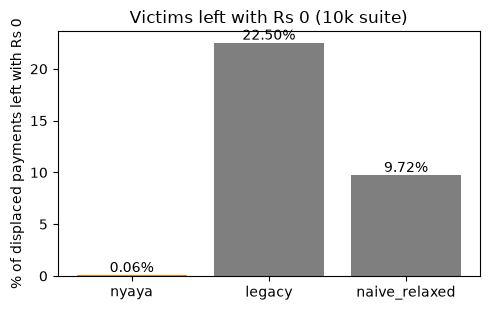

In [3]:
h = {k: 100 * v["victims_left_with_zero_rate"] for k, v in sim["metrics"].items()}
plt.figure(figsize=(5, 3.2)); plt.bar(list(h), list(h.values()), color=["tab:orange", "tab:gray", "tab:gray"][:len(h)])
for i, v in enumerate(h.values()):
    plt.text(i, v, f"{v:.2f}%", ha="center", va="bottom")
plt.ylabel("% of displaced payments left with Rs 0"); plt.title("Victims left with Rs 0 (10k suite)")
plt.tight_layout(); plt.show()

## Fairness by synthetic income band (never a model input; target ratio <= 1.25)

In [4]:
f = sim["fairness"]
print("ALL payments    -> freeze ratio:", round(f["max_min_freeze_ratio"], 3), "| review ratio:", round(f["max_min_review_ratio"], 3), "| target met:", f["target_met"])
lo = f.get("legitimate_only")
if lo:
    print("LEGIT payments  -> freeze ratio:", lo["max_min_freeze_ratio"] and round(lo["max_min_freeze_ratio"], 3),
          "| review ratio:", lo["max_min_review_ratio"] and round(lo["max_min_review_ratio"], 3), "| target met:", lo["target_met"])
pd.concat({"all": pd.DataFrame(f["by_sender_income_band"]).T,
           "legitimate_only": pd.DataFrame((lo or {}).get("by_sender_income_band", {})).T})

ALL payments    -> freeze ratio: 1.483 | review ratio: 1.354 | target met: False
LEGIT payments  -> freeze ratio: 1.304 | review ratio: 1.61 | target met: False


n  freeze_rate  review_rate
all             low   5014.0     0.073793     0.025130
                mid   3760.0     0.057713     0.028723
                high  1226.0     0.049755     0.021207
legitimate_only low   4605.0     0.005212     0.019761
                mid   3532.0     0.006795     0.024915
                high  1163.0     0.006019     0.015477

## Is the legacy baseline real? Score range per population vs its threshold

In [5]:
ld = sim["legacy_diagnostics"]
print("threshold", ld["threshold"], "| score range", ld["score_min"], "-", ld["score_max"], "| threshold above max:", ld["threshold_above_max"])
pd.DataFrame(ld["by_population"]).T

threshold 0.035403575748205185 | score range 4.054107193951495e-05 - 0.9951743483543396 | threshold above max: False


,n,flag_rate,q50,q90,q99,max,share_saturated_ge_0.999
displaced,1800.0,0.225000,0.006036,0.220204,0.972266,0.995174,0.0
normal,7500.0,0.013867,0.000330,0.002639,0.057663,0.896142,0.0
syndicate,700.0,0.354286,0.024163,0.084787,0.259611,0.349015,0.0


## Cost of the zone rule: account takeovers with the rule on and off (policy choice, not a free win)

In [6]:
za = sim["ato_zone_rule_audit"]
print(za["source"], "| rows", za["rows"], "| spoofed-zone rows", za["spoofed_zone_rows"], "| fraud total Rs", round(za["fraud_total_rupees"]))
pd.DataFrame({k: za[k] for k in ["zone_rule_off", "zone_rule_on"]}).T

independent file eval, all population == 'ato' rows | rows 900 | spoofed-zone rows 98 | fraud total Rs 26831306


,hold_rate,review_rate,release_rate,leakage_rupees,spoofed_zone_hold_rate,spoofed_zone_leakage_rupees
zone_rule_off,0.887778,0.017778,0.094444,252462.22,0.693878,98962.07
zone_rule_on,0.812222,0.076667,0.111111,428424.69,0.000000,274924.54


## Red team: we attacked our own system

In [7]:
rt = json.loads((ART / "sim" / "redteam.json").read_text())
rows = [{"variant": "base", **{k: rt["base"][k] for k in ["rows", "detection_rate", "hold_rate", "review_rate",
         "mean_p_mule", "strongest_remaining_feature"]}}]
for v in rt["variants"]:
    rows.append({"variant": v["variant"], **{k: v[k] for k in ["rows", "detection_rate", "hold_rate", "review_rate",
                 "mean_p_mule", "strongest_remaining_feature"]}, "change_vs_base": v["detection_change_vs_base"]})
pd.DataFrame(rows).round(4)

,variant,rows,detection_rate,hold_rate,review_rate,mean_p_mule,strongest_remaining_feature,change_vs_base
0,base,6000,0.9383,0.8497,0.0887,0.8853,forward_within_10m_ratio,NaN
1,smurf,6000,0.8040,0.5280,0.2760,0.6154,forward_within_10m_ratio,-0.1343
2,device_spoof,6000,0.8352,0.6105,0.2247,0.6611,forward_within_10m_ratio,-0.1032
3,slow_drip,6000,0.7702,0.4555,0.3147,0.5786,fan_in_15m,-0.1682


## Model B: NNPA vs CPU (median latency incl. host-device transfer)

In [8]:
b = json.loads((ART / "bench" / "throughput.json").read_text())
print(b["model"], "| nnpa available:", b["nnpa_available"], "| max |logit diff| cpu vs nnpa:",
      b.get("max_abs_logit_diff_cpu_vs_nnpa"))
pd.DataFrame(b["results"]).pivot(index="batch", columns="device", values=["p50_ms", "decisions_per_s"])

model_b B-mlp-1 | nnpa available: True | max |logit diff| cpu vs nnpa: 0.17285919189453125


p50_ms        decisions_per_s           
device    cpu   nnpa             cpu       nnpa
batch                                          
1       0.026  0.035         38625.0    28350.3
100     0.043  0.040       2340221.6  2483577.2
10000   1.696  4.160       5896814.0  2403980.5